# Text-to-Image Generation with Stable Diffusion, Evaluated with CLIP Score

This notebook generates images from text prompts with a pretrained Stable Diffusion model (`dreamlike-art/dreamlike-diffusion-1.0`) through Hugging Face's `diffusers` library, and measures how well each image matches its prompt using **CLIP score**.

What it covers:

* generating images from text prompts with `StableDiffusionPipeline`
* the main inference parameters: number of denoising steps, guidance scale, output resolution, negative prompting and images per prompt
* a quantitative study of how each parameter affects prompt adherence, using a fixed seed and a fixed set of evaluation prompts so that settings are compared fairly

**Runtime:** use a GPU runtime (in Colab: *Runtime > Change runtime type > T4 GPU*). The full notebook takes roughly 10 to 15 minutes on a T4.

In [1]:
!pip install -q diffusers transformers accelerate

In [2]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline
from transformers import CLIPModel, CLIPProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
print("Device:", device)
if device == "cpu":
    print("Warning: no GPU found. Generation will be very slow on CPU.")

Device: cuda


## 1. Load the Stable Diffusion pipeline

`StableDiffusionPipeline` wraps the three parts of a latent diffusion model: the CLIP text encoder that turns the prompt into conditioning embeddings, the UNet that removes noise step by step in latent space, and the VAE decoder that turns the final latent into an image. The scheduler controls how noise is removed at each step.

In [3]:
model_id = "dreamlike-art/dreamlike-diffusion-1.0"

pipe = StableDiffusionPipeline.from_pretrained(model_id, torch_dtype=dtype, use_safetensors=True)
pipe = pipe.to(device)
pipe.set_progress_bar_config(disable=True)

print("Scheduler:", type(pipe.scheduler).__name__)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/511 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Scheduler: DDIMScheduler


## 2. Load CLIP for evaluation

**CLIP score** measures text-image alignment. CLIP embeds the image and the prompt into a shared space, and the score is the cosine similarity between the two embeddings, scaled by 100 and clipped at zero:

$$\text{CLIPScore}(I, T) = 100 \cdot \max\big(\cos(E_I, E_T),\ 0\big)$$

A higher score means the image follows the prompt more closely. We use `openai/clip-vit-large-patch14`, the CLIP variant commonly used for this metric. Note that CLIP score measures prompt adherence, not visual quality or realism.

In [4]:
clip_id = "openai/clip-vit-large-patch14"
clip_model = CLIPModel.from_pretrained(clip_id).to(device).eval()
clip_processor = CLIPProcessor.from_pretrained(clip_id)


@torch.no_grad()
def clip_score(images, prompt):
    """Return one CLIP score per image for the given prompt."""
    inputs = clip_processor(text=[prompt], images=images, return_tensors="pt",
                            padding=True, truncation=True).to(device)
    out = clip_model(**inputs)
    img = out.image_embeds.float().cpu().numpy()
    txt = out.text_embeds.float().cpu().numpy()
    img = img / np.linalg.norm(img, axis=-1, keepdims=True)
    txt = txt / np.linalg.norm(txt, axis=-1, keepdims=True)
    return (100 * np.clip(img @ txt.T, 0, None)).ravel().tolist()

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

## 3. Generation helper

Every image is generated from a fixed seed, so the only thing that changes between two settings is the parameter being studied. When several images are requested per prompt, image `i` uses seed `SEED + i`.

In [5]:
SEED = 42


def generate(prompt, seed=SEED, show=True, title=None, **params):
    """Generate images for one prompt, score them with CLIP and optionally display them."""
    n = params.get("num_images_per_prompt", 1)
    generators = [torch.Generator(device=device).manual_seed(seed + i) for i in range(n)]
    images = pipe(prompt, generator=generators, **params).images
    scores = clip_score(images, prompt)

    if show:
        fig, axes = plt.subplots(1, len(images), figsize=(4 * len(images), 4), squeeze=False)
        for ax, img, s in zip(axes[0], images, scores):
            ax.imshow(img)
            ax.axis("off")
            ax.set_title(f"CLIP score: {s:.2f}")
        if title:
            fig.suptitle(title)
        plt.tight_layout()
        plt.show()
    return images, scores

## 4. Basic text-to-image generation

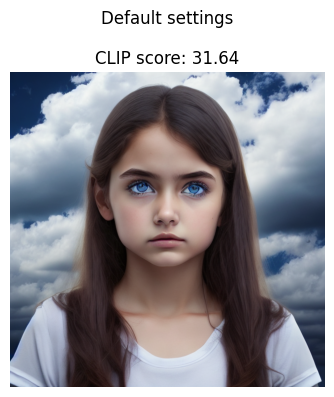

[PROMPT]: a girl in a dark blue shirt with brown eyes, white background, cloudy sky
CLIP score: 31.64


In [6]:
prompt = "a girl in a dark blue shirt with brown eyes, white background, cloudy sky"
images, scores = generate(prompt, title="Default settings")
print("[PROMPT]:", prompt)
print("CLIP score:", round(scores[0], 2))

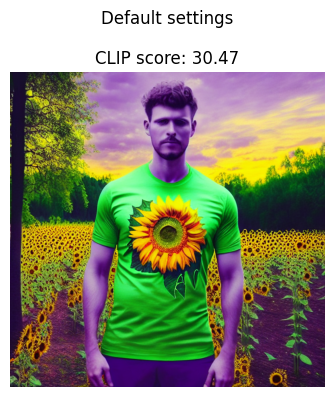

[PROMPT]: a person in a light green shirt with a sunflower print, purple sky above a green forest
CLIP score: 30.47


In [7]:
prompt2 = "a person in a light green shirt with a sunflower print, purple sky above a green forest"
images, scores = generate(prompt2, title="Default settings")
print("[PROMPT]:", prompt2)
print("CLIP score:", round(scores[0], 2))

## 5. Parameter study

Each setting is run on the same four evaluation prompts with the same seed, and the CLIP score is recorded for every image. The first prompt of each setting is displayed so the visual effect can be compared alongside the numbers.

In [8]:
eval_prompts = [
    "a teacher walking inside a classroom",
    "a red vintage car parked on a cobblestone street at sunset",
    "a bowl of fresh fruit on a wooden kitchen table",
    "a lighthouse on a rocky coast during a storm",
]

results = []


def run(experiment, setting, prompts=eval_prompts, show_first=True, **params):
    for i, p in enumerate(prompts):
        _, scores = generate(p, show=(show_first and i == 0),
                             title=f"{experiment}: {setting}", **params)
        for s in scores:
            results.append({"experiment": experiment, "setting": str(setting),
                            "prompt": p, "clip_score": s})

### 5.1 Number of inference steps

More denoising steps give the model more chances to refine the image, at a higher compute cost.

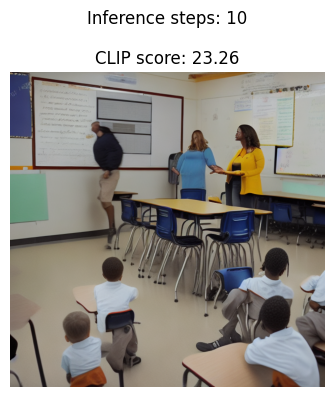

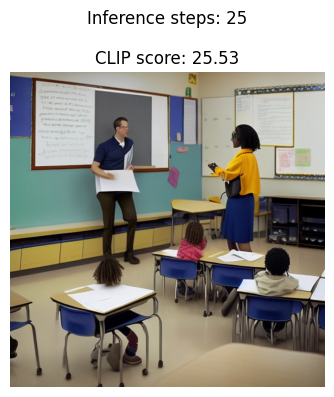

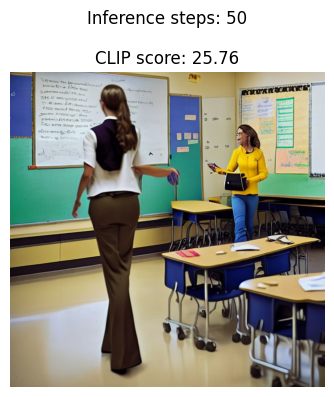

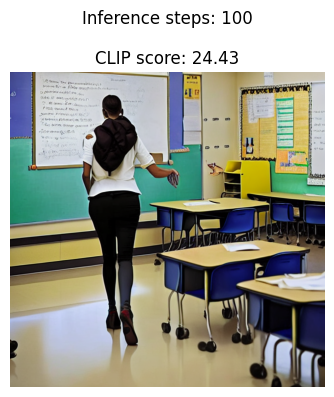

In [9]:
for steps in [10, 25, 50, 100]:
    run("Inference steps", steps, num_inference_steps=steps)

### 5.2 Guidance scale

Classifier-free guidance controls how strongly the text conditioning pushes the denoising. Low values give more freedom to the model, high values follow the prompt more literally but can oversaturate the image.

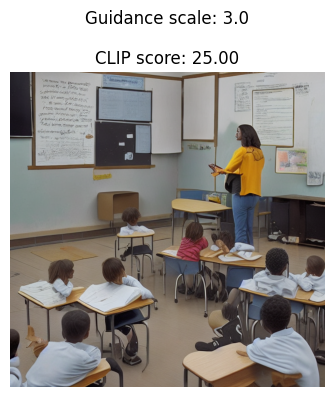

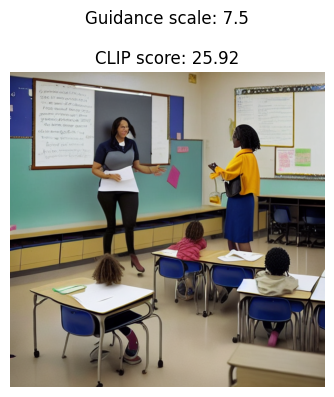

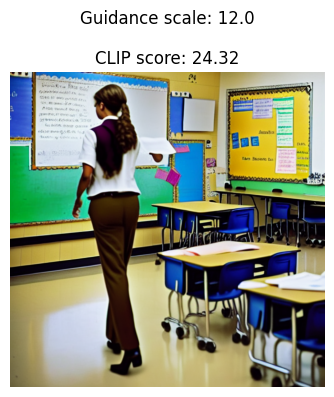

In [10]:
for g in [3.0, 7.5, 12.0]:
    run("Guidance scale", g, guidance_scale=g, num_inference_steps=30)

### 5.3 Output resolution

The model was trained mostly at 512x512, so other aspect ratios change the composition the model produces.

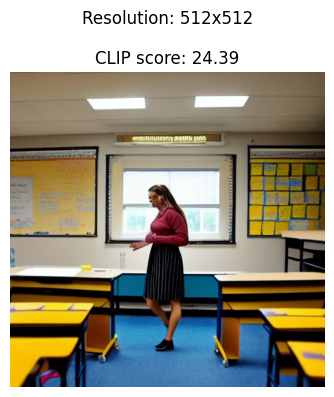

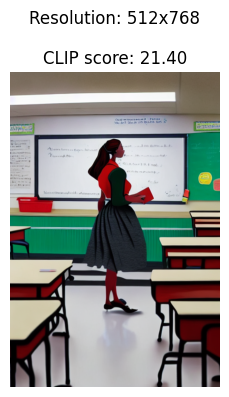

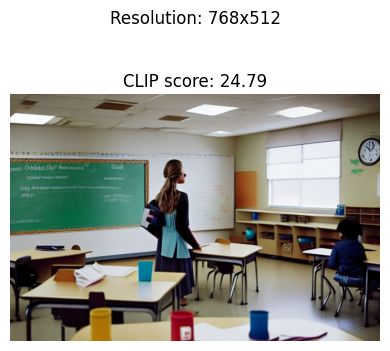

In [11]:
for w, h in [(512, 512), (512, 768), (768, 512)]:
    run("Resolution", f"{w}x{h}", width=w, height=h, num_inference_steps=30)

### 5.4 Negative prompting

A negative prompt tells the model which features to steer away from during guidance.

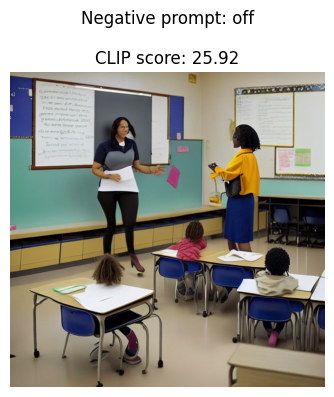

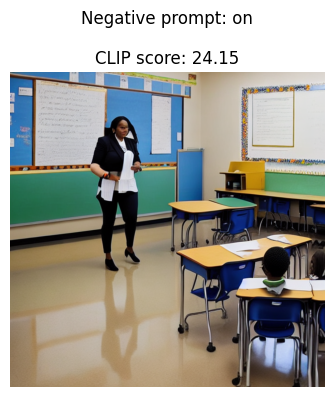

In [12]:
negative = "ugly, distorted, blurry, low quality, deformed"
for neg in [None, negative]:
    run("Negative prompt", "off" if neg is None else "on",
        negative_prompt=neg, num_inference_steps=30)

### 5.5 Images per prompt (seed variation)

Generating several images per prompt with different seeds shows how much the CLIP score varies from the random starting noise alone, which gives a reference for how large a difference between settings has to be before it is meaningful.

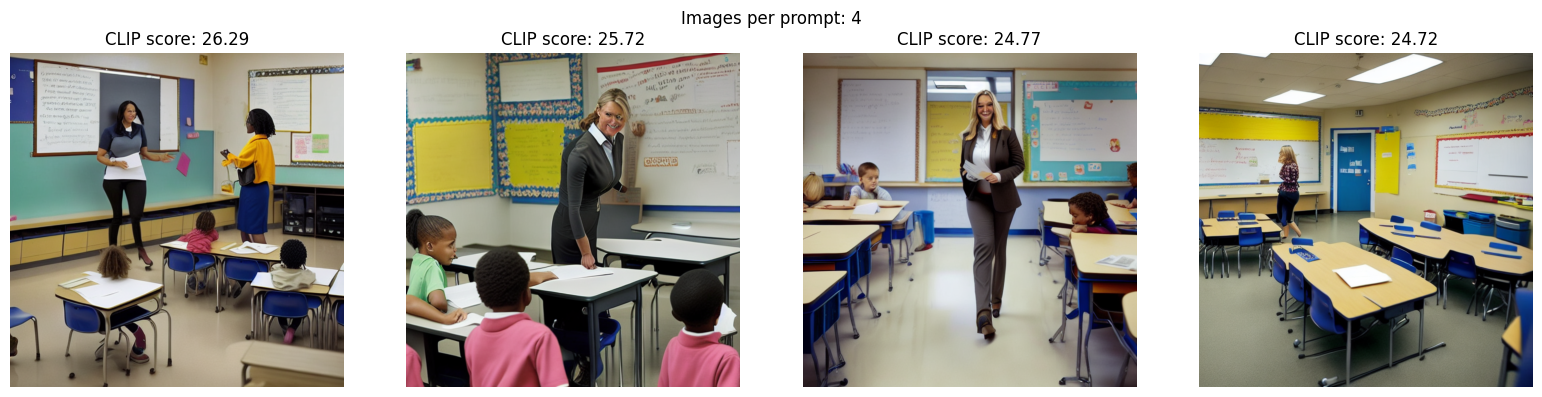

CLIP score spread across 4 seeds, per prompt:


,mean,std,min,max
prompt,,,,
a bowl of fresh fruit on a wooden kitchen table,25.43,0.89,24.38,26.54
a lighthouse on a rocky coast during a storm,27.79,0.45,27.43,28.45
a red vintage car parked on a cobblestone street at sunset,32.24,2.18,30.27,34.16
a teacher walking inside a classroom,25.37,0.76,24.72,26.29


In [13]:
run("Images per prompt", 4, num_images_per_prompt=4, num_inference_steps=30)

seed_df = pd.DataFrame([r for r in results if r["experiment"] == "Images per prompt"])
print("CLIP score spread across 4 seeds, per prompt:")
seed_df.groupby("prompt")["clip_score"].agg(["mean", "std", "min", "max"]).round(2)

## 6. Results

In [16]:
df = pd.DataFrame(results)
summary = (df.groupby(["experiment", "setting"], sort=False)["clip_score"]
             .agg(["mean", "std", "count"]).round(2))
summary

mean   std  count
experiment        setting                    
Inference steps   10       27.93  3.88      4
                  25       28.63  4.01      4
                  50       28.81  3.93      4
                  100      28.84  4.75      4
Guidance scale    3.0      26.86  3.44      4
                  7.5      28.51  3.77      4
                  12.0     28.42  3.95      4
Resolution        512x512  28.62  4.40      4
                  512x768  25.66  3.89      4
                  768x512  28.31  4.94      4
Negative prompt   off      28.51  3.77      4
                  on       27.26  3.75      4
Images per prompt 4        27.71  3.10     16

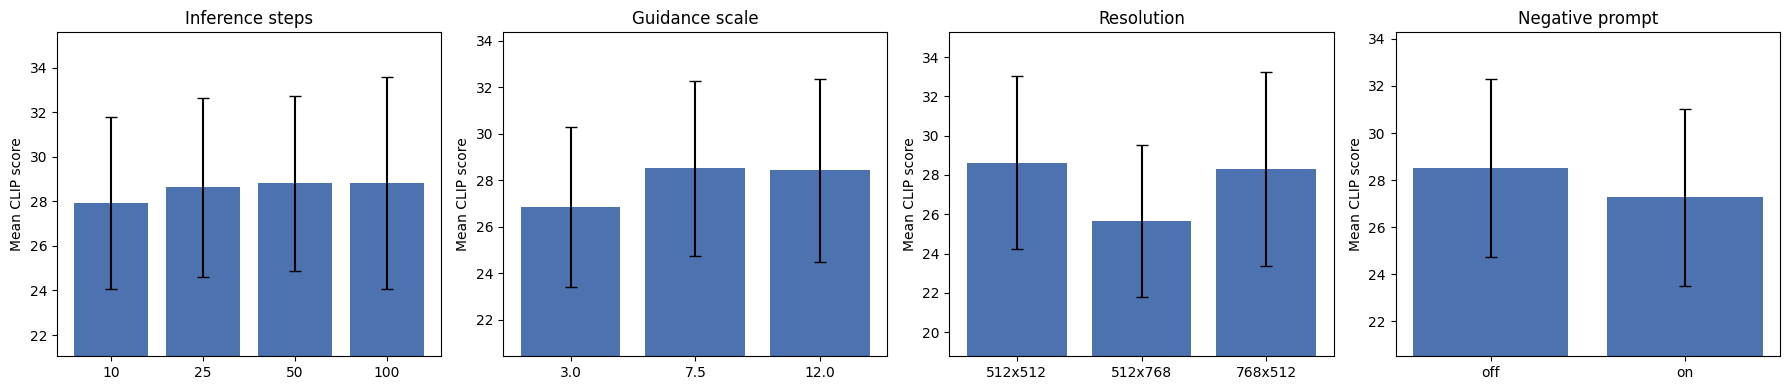

Saved all scores to clip_scores.csv


In [15]:
experiments = [e for e in df["experiment"].unique() if e != "Images per prompt"]
fig, axes = plt.subplots(1, len(experiments), figsize=(4.5 * len(experiments), 4), squeeze=False)

for ax, exp in zip(axes[0], experiments):
    grouped = df[df["experiment"] == exp].groupby("setting", sort=False)["clip_score"]
    means, stds = grouped.mean(), grouped.std().fillna(0)
    ax.bar(means.index, means.values, yerr=stds.values, capsize=4, color="#4C72B0")
    ax.set_title(exp)
    ax.set_ylabel("Mean CLIP score")
    low = (means - stds).min()
    ax.set_ylim(max(0, low - 3), (means + stds).max() + 2)

plt.tight_layout()
plt.show()

df.to_csv("clip_scores.csv", index=False)
print("Saved all scores to clip_scores.csv")

## 7. Notes on interpretation

* Differences between settings should be read against the seed variation in section 5.5. A gap smaller than the seed spread is not meaningful with only four prompts.
* CLIP score only measures text-image alignment. A blurry image that clearly shows the right objects can still score well, so the displayed images should be checked alongside the numbers.
* A fuller evaluation would add an image quality metric such as FID against a reference image set, and a larger prompt set.